# 11. EP3: datos de desarrollo y detector de huecos (F1 y F2)

**Qué hacemos.** Juntamos los 41 segmentos de EP2 (33 de train y 8 de test) en una sola tabla de desarrollo, fijamos los folds y volvemos a correr el detector de huecos por cámara con los parámetros de EP2 sin recalcularlos.

**Analogía.** En EP2 guardamos 8 segmentos como examen sorpresa. Ya los miramos seis veces, así que en EP3 ya no son un examen ciego: los usamos como un tercio más de material de estudio, y el examen ciego de verdad serán segmentos nuevos que todavía no existen.

**Plan v3 (congelado antes de ver resultados):** población principal con |azimut| <= 100°, target `sin_camara`, CV externa StratifiedGroupKFold(5) por segmento, semilla 42.

Este notebook **muestra artefactos**: no recalcula nada salvo que `RECALCULAR = True`.

In [1]:
from pathlib import Path
import json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "conf").exists() and (p / "data").exists()), Path("C:/Users/maico/waymo-evaluacion"))
sys.path.insert(0, str(RAIZ / "src"))
REP, IMG, APP = RAIZ / "data/08_reporting_ep3", RAIZ / "images/ep3", RAIZ / "data/09_app_ep3"
IMG.mkdir(parents=True, exist_ok=True)
RECALCULAR = False          # True: vuelve a correr los scripts de esta fase (puede tardar mucho; escribe solo en *_ep3)
SEMILLA = 42
EN_MUESTRA = "en muestra: 41 segmentos, parámetros del detector ajustados con los mismos datos; post hoc, no pre-declarado; sin validación con datos nuevos"
GANANCIA_C = "La ganancia del brazo C sale de 2 celdas cámara x segmento, una de ellas en el segmento donde se descubrió el hueco."
AZUL, NARANJA, GRIS, VERDE, ROJO = "#2a78d6", "#e07b39", "#8a8a8a", "#6a994e", "#c0392b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

from waymo_evaluacion.ep3.plan import verificar_plan_v3
print("Plan v3 verificado (sha256):", ", ".join(verificar_plan_v3(RAIZ)))


def coma(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")


def pct(x, d=1):
    return f"{100 * x:.{d}f} %".replace(".", ",")


def miles(x):
    return f"{int(round(x)):,}".replace(",", ".")


def guardar_fig(fig, nombre):
    fig.savefig(IMG / f"{nombre}.png", dpi=130, bbox_inches="tight")


def correr(script, *args):
    r = subprocess.run([sys.executable, "-X", "utf8", str(RAIZ / "scripts/ep3" / script), *args], capture_output=True, text=True, cwd=RAIZ)
    print(r.stdout[-1500:], r.stderr[-800:])
    assert r.returncode == 0, f"{script} fallo"

Plan v3 verificado (sha256): plan_v3.md, plan_v3.json


In [2]:
if RECALCULAR:
    correr("f1_datos.py")
    correr("f2_detector.py")
dev = pd.read_parquet(RAIZ / "data/05_model_input_ep3/dev_41.parquet")
pp = dev[dev["en_zona_principal"]]
r1 = json.loads((REP / "f1_resumen.json").read_text(encoding="utf-8"))
print(f"Filas totales (<= 120 grados): {miles(r1['filas_total_120'])} | población principal: {miles(r1['filas_principal'])} filas, {miles(r1['positivos_principal'])} positivos ({pct(r1['prevalencia_principal'])})")
print(f"Segmentos: {r1['segmentos']} ({r1['segmentos_train']} train de EP2 + {r1['segmentos_test']} test de EP2)")
print("Test de EP2, principal (filas, positivos):", r1["test_principal"], "| 120 grados:", r1["test_120"], "(iguales a la tabla del plan de EP2)")

Filas totales (<= 120 grados): 85.852 | población principal: 80.571 filas, 17.102 positivos (21,2 %)
Segmentos: 41 (33 train de EP2 + 8 test de EP2)
Test de EP2, principal (filas, positivos): [16062, 3734] | 120 grados: [17297, 4378] (iguales a la tabla del plan de EP2)


## 1. Los 41 segmentos: cuántas filas y cuántos positivos hay en cada uno

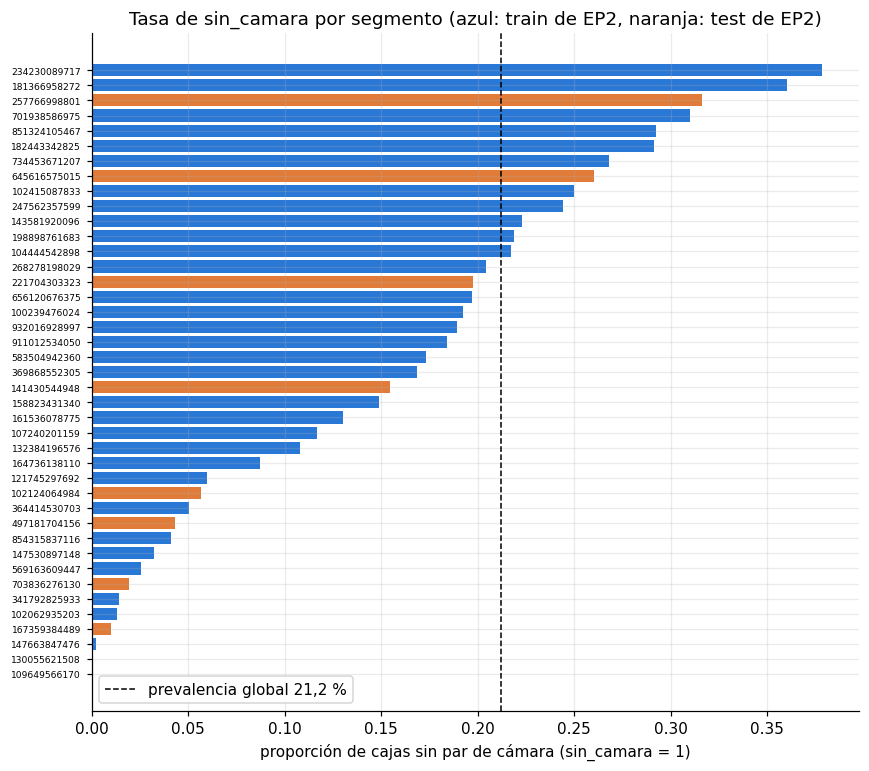

**Lectura (generada).** La tasa va de 0,0 % a 37,9 % según el segmento. El segmento `181366958272` aporta 2.228 positivos (13,0 % de todos): por eso la validación se hace por segmento y se reporta siempre cuántos segmentos gana cada método.

In [3]:
seg = pp.groupby("seg").agg(grupo=("grupo", "first"), ubicacion=("location", "first"), momento=("time_of_day", "first"), filas=("sin_camara", "size"), positivos=("sin_camara", "sum"))
seg["tasa"] = seg["positivos"] / seg["filas"]
seg = seg.sort_values("tasa")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(seg.index, seg["tasa"], color=[AZUL if g == "train" else NARANJA for g in seg["grupo"]])
ax.axvline(pp["sin_camara"].mean(), color="k", ls="--", lw=1, label=f"prevalencia global {pct(pp['sin_camara'].mean())}")
ax.set_xlabel("proporción de cajas sin par de cámara (sin_camara = 1)"); ax.set_title("Tasa de sin_camara por segmento (azul: train de EP2, naranja: test de EP2)")
ax.legend(); ax.tick_params(axis="y", labelsize=6)
guardar_fig(fig, "11_tasa_por_segmento"); plt.show()
top = seg.sort_values("positivos", ascending=False).iloc[0]
display(Markdown(f"**Lectura (generada).** La tasa va de {pct(seg['tasa'].min())} a {pct(seg['tasa'].max())} según el segmento. El segmento `{top.name}` aporta {miles(int(top['positivos']))} positivos "
                 f"({pct(top['positivos'] / seg['positivos'].sum())} de todos): por eso la validación se hace por segmento y se reporta siempre cuántos segmentos gana cada método."))

## 2. Conjuntos de variables y folds
Tres conjuntos declarados en el plan (V16, V_OBS, V_OBS_TAM); el conjunto es un hiperparámetro de la búsqueda. Los folds se arman por segmento y se estratifican por `sin_camara` para que ningún segmento quede repartido entre entrenamiento y validación.

In [4]:
cj = json.loads((RAIZ / "data/05_model_input_ep3/conjuntos_variables.json").read_text(encoding="utf-8"))
display(pd.DataFrame({"conjunto": list(cj), "variables": [len(v) for v in cj.values()], "lista": [", ".join(v) for v in cj.values()]}))
f = r1["folds"]["fold_s42"]
display(pd.DataFrame({"filas": f["filas"], "segmentos": f["segmentos"], "prevalencia": f["prevalencia"]}))
print("Segmentos presentes en más de un fold (debe ser 0):", {k: v["segmentos_en_mas_de_un_fold"] for k, v in r1["folds"].items()})

,conjunto,variables,lista
0,V16,16,"box_center_x, box_center_y, box_center_z, azim..."
1,V_OBS,4,"num_lidar_points, num_top_lidar_points, densid..."
2,V_OBS_TAM,10,"num_lidar_points, num_top_lidar_points, densid..."
3,VISTA_OBS,4,"num_lidar_points, num_top_lidar_points, densid..."
4,VISTA_TAMANO,6,"box_length, box_width, box_height, volumen_caj..."
5,VISTA_POSICION,7,"box_center_x, box_center_y, box_center_z, azim..."
6,V_MIN3,3,"num_lidar_points, num_top_lidar_points, azimut..."


,filas,segmentos,prevalencia
0,14968,7,0.2760
1,14971,9,0.1359
2,14950,9,0.1982
3,15659,7,0.2794
4,20023,9,0.1797


Segmentos presentes en más de un fold (debe ser 0): {'fold_s42': 0, 'fold_s43': 0, 'fold_s44': 0}


## 3. Los modelos congelados de EP2 se reproducen (control de que reconstruimos bien los datos)

In [5]:
rep = pd.read_csv(REP / "f1_reproduccion_pred_test.csv")
display(rep)
print(f"Diferencia máxima absoluta contra pred_test_B.parquet de EP2: {rep['dif_max_abs'].max():.2e} (tolerancia 1e-9)")

,modelo,dif_max_abs,ok_1e-9
0,Regresion logistica,0.000000e+00,True
1,HGB,0.000000e+00,True
2,Random Forest,5.551115e-16,True
3,Modelo minimo (LR 3 variables),0.000000e+00,True
4,Regla: menos puntos LiDAR,0.000000e+00,True
5,Regla: menos puntos top,0.000000e+00,True


Diferencia máxima absoluta contra pred_test_B.parquet de EP2: 5.55e-16 (tolerancia 1e-9)


## 4. Filtro 1: detector de huecos por cámara
Reglas de EP2, sin recalcular: el rango de azimut de cada cámara es el p5-p95 de las cajas con par en train; la mediana de la tasa por cámara se calcula con los 41 segmentos; una celda (segmento, cámara) tiene **hueco** si su tasa es menor al 25 % de la mediana y hay al menos 100 cajas en el rango.

**Analogía.** Es como revisar un cuaderno de recibos por cámara: si en un segmento una cámara casi no tiene recibos pareados aunque debería, no conviene revisar recibo por recibo, sino avisar que falta toda una caja de recibos.

,camara,az_p5,az_p95,mediana_tasa
0,1,-20.982,20.062,0.880
1,2,20.365,63.096,0.902
2,3,-60.510,-19.496,0.917
3,4,64.393,109.196,0.913
4,5,-105.250,-57.558,0.914


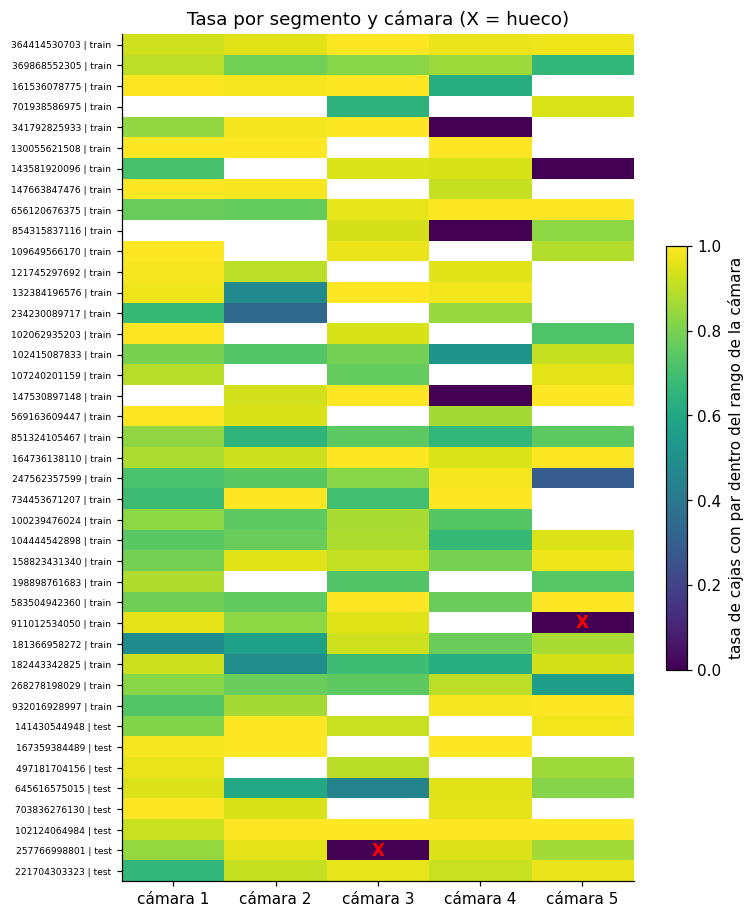

,segmento,grupo,ubicacion,momento,camara,tasa,mediana_camara,umbral,cajas_en_rango,cajas_afectadas_poblacion_principal,positivos_afectados
0,911012534050,train,location_sf,Day,5 (lateral der.),0.0,0.914,0.228,300,268,227
1,257766998801,test,location_sf,Day,3 (frontal der.),0.0,0.917,0.229,1677,1677,1338


**Lectura (generada).** El detector marca 2 celdas con hueco, las mismas que en EP2 (diferencia máxima contra los CSV de EP2: 1.1e-16). Esas celdas contienen 1.565 de los 17.102 positivos (9,2 %) en 1.945 cajas de la población principal. **Post hoc, no pre-declarado** (el apéndice M de EP2 lo descubrió después de abrir el test).

In [6]:
par = json.loads((RAIZ / "data/06_models_ep3/detector_params_v3.json").read_text(encoding="utf-8"))
display(pd.DataFrame({"camara": list(par["rangos"]), "az_p5": [v[0] for v in par["rangos"].values()], "az_p95": [v[1] for v in par["rangos"].values()],
                      "mediana_tasa": [par["medianas_ref"][f"c{c}"] for c in par["rangos"]]}).round(3))
cel = pd.read_csv(REP / "f2_tasa_segmento_camara.csv", dtype={"seg": str})
cams = [1, 2, 3, 4, 5]
mat = cel[[f"tasa_c{c}" for c in cams]].to_numpy(float)
fig, ax = plt.subplots(figsize=(7.5, 10))
im = ax.imshow(np.ma.masked_invalid(mat), aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(5), [f"cámara {c}" for c in cams]); ax.set_yticks(range(len(cel)), [f"{s} | {g}" for s, g in zip(cel["seg"], cel["grupo"])], fontsize=6)
for i in range(len(cel)):
    for j, c in enumerate(cams):
        if cel.loc[i, f"hueco_c{c}"]:
            ax.text(j, i, "X", ha="center", va="center", color="red", fontweight="bold", fontsize=11)
fig.colorbar(im, ax=ax, shrink=0.5, label="tasa de cajas con par dentro del rango de la cámara"); ax.set_title("Tasa por segmento y cámara (X = hueco)"); ax.grid(False)
guardar_fig(fig, "11_mapa_de_calor_huecos"); plt.show()
lista = pd.read_csv(REP / "lista_A_huecos.csv", dtype={"segmento": str})
display(lista.round(3))
r2 = json.loads((REP / "f2_resumen.json").read_text(encoding="utf-8"))
display(Markdown(f"**Lectura (generada).** El detector marca {r2['n_pares_con_hueco']} celdas con hueco, {'las mismas que en EP2' if r2['pares_iguales_a_ep2'] else 'DISTINTAS a las de EP2'} "
                 f"(diferencia máxima contra los CSV de EP2: {r2['dif_max_tabla_vs_ep2']:.1e}). Esas celdas contienen {miles(r2['positivos_en_hueco_principal'])} de los {miles(r1['positivos_principal'])} positivos "
                 f"({pct(r2['positivos_en_hueco_principal'] / r1['positivos_principal'])}) en {miles(r2['cajas_en_hueco_principal'])} cajas de la población principal. **Post hoc, no pre-declarado** (el apéndice M de EP2 lo descubrió después de abrir el test)."))

## 5. Baselines simples (reglas), con IC 95 % por segmentos

In [7]:
b = pd.read_csv(REP / "f2_baselines_reglas_41.csv")
vista = pd.DataFrame({"método": b["metodo"]})
for k in ["AUC", "PR-AUC", "Captura@20", "Fraccion_80"]:
    vista[k] = [f"{coma(r[k])} ({coma(r[k + '_lo'])} a {coma(r[k + '_hi'])})" for _, r in b.iterrows()]
display(vista)
g = pd.read_csv(REP / "f2_baselines_reglas_por_grupo.csv")
display(g[g["metodo"] == "Regla: menos puntos top"].round(3))
display(Markdown("**Nota.** La regla geométrica (azimut > 105° primero) coincide con la de puntos LiDAR en la población principal porque ahí |azimut| <= 100°: nunca se activa. "
                 "Las reglas no se ajustan, así que no hay predicción fuera de fold: se evalúan sobre los 41 segmentos."))

,método,AUC,PR-AUC,Captura@20,Fraccion_80
0,Regla: menos puntos top,"0,823 (0,725 a 0,900)","0,672 (0,558 a 0,769)","0,619 (0,533 a 0,723)","0,446 (0,279 a 0,704)"
1,Regla: menos puntos LiDAR,"0,820 (0,723 a 0,897)","0,667 (0,553 a 0,763)","0,616 (0,532 a 0,719)","0,453 (0,287 a 0,712)"
2,Regla geometrica (azimut > 105 primero),"0,820 (0,723 a 0,897)","0,667 (0,553 a 0,763)","0,616 (0,532 a 0,719)","0,453 (0,287 a 0,712)"


,grupo,metodo,AUC,PR-AUC,Captura@20,Fraccion_80,filas,prevalencia
0,train,Regla: menos puntos top,0.862,0.704,0.649,0.378,64509,0.207
3,test,Regla: menos puntos top,0.684,0.558,0.503,0.790,16062,0.232


**Nota.** La regla geométrica (azimut > 105° primero) coincide con la de puntos LiDAR en la población principal porque ahí |azimut| <= 100°: nunca se activa. Las reglas no se ajustan, así que no hay predicción fuera de fold: se evalúan sobre los 41 segmentos.

## 6. EDA y calidad de datos (post hoc, descriptivo; fase 12.4)
Tasa de `sin_camara` por tramo de puntos del LiDAR superior, azimut, distancia (quintiles) y clase, con IC 95 % por segmentos, y revisión de nulos, duplicados y atípicos. **Lo que más explica `sin_camara` son los puntos del LiDAR.**

,variable,tramo,cajas,positivos,tasa,IC,segmentos
0,puntos_top,0-5,10362,8303,"80,1 %","68,8 % a 87,5 %",40
1,puntos_top,6-10,5521,2211,"40,0 %","29,4 % a 50,3 %",40
2,puntos_top,11-20,10781,1992,"18,5 %","12,0 % a 26,3 %",41
3,puntos_top,21-50,20657,2349,"11,4 %","7,8 % a 14,9 %",41
4,puntos_top,51-100,13720,779,"5,7 %","2,9 % a 8,6 %",40
5,puntos_top,>100,19530,1468,"7,5 %","1,0 % a 16,4 %",40
6,azimut_abs_deg,0-20,37754,8454,"22,4 %","16,6 % a 27,4 %",38
7,azimut_abs_deg,20-40,19220,4020,"20,9 %","14,6 % a 28,0 %",40
8,azimut_abs_deg,40-60,10474,2151,"20,5 %","12,1 % a 29,2 %",41
9,azimut_abs_deg,60-80,7071,1377,"19,5 %","13,1 % a 25,8 %",40


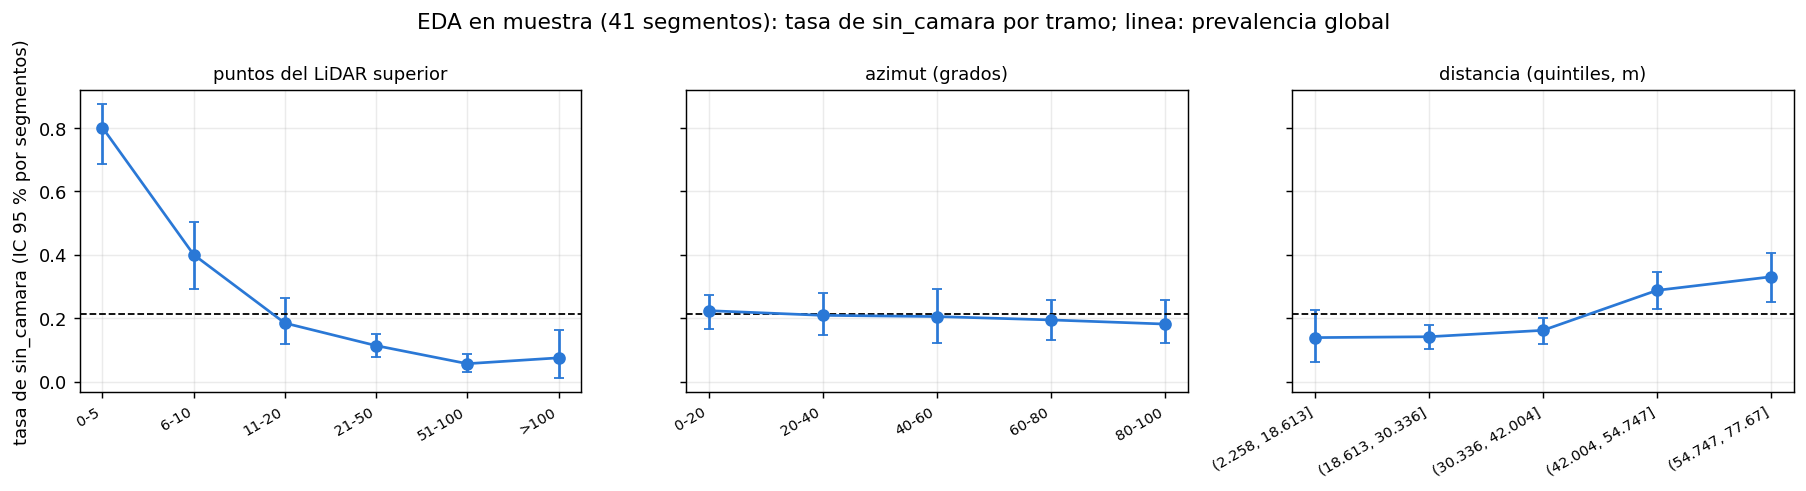

,variable,pct_nulos,atipicos_bajos,atipicos_altos,pct_atipicos
0,box_center_x,0.0,0,0,0.000
1,box_center_y,0.0,502,1369,0.023
2,box_center_z,0.0,2791,2396,0.064
3,azimut_abs_deg,0.0,0,932,0.012
4,distancia_m,0.0,0,0,0.000
5,box_length,0.0,140,2084,0.028
6,box_width,0.0,552,1059,0.020
7,box_height,0.0,6127,756,0.085
8,volumen_caja,0.0,0,1432,0.018
9,num_lidar_points,0.0,0,8896,0.110


Nulos: 0 | llaves duplicadas: 0 | cajas con 0 puntos LiDAR: 4.590 (5,7 %) | con 0 puntos top: 4.757, de las cuales 90,5 % no tienen pareja


**Lectura (generada, post hoc).** La tasa va de 80,1 % con 0 a 5 puntos del sensor superior a 5,7 % con 51 a 100. Sin nulos ni llaves duplicadas; los atípicos de puntos y densidad son cajas muy cercanas, no errores, y no se eliminaron.

In [8]:
if RECALCULAR:
    correr("f12_analisis_muestra.py")
eda = pd.read_csv(REP / "f12_eda_tasas.csv")
vista = eda.assign(tasa=eda["tasa"].map(pct), IC=[f"{pct(a)} a {pct(b)}" for a, b in zip(eda["ic_lo"], eda["ic_hi"])])[["variable", "tramo", "cajas", "positivos", "tasa", "IC", "segmentos"]]
display(vista)
from IPython.display import Image
display(Image(filename=str(IMG / "12_eda_tasas.png")))
cal = pd.read_csv(REP / "f12_eda_calidad.csv"); cres = json.loads((REP / "f12_eda_calidad_resumen.json").read_text(encoding="utf-8"))
display(cal[["variable", "pct_nulos", "atipicos_bajos", "atipicos_altos", "pct_atipicos"]].round(3))
print(f"Nulos: {cres['nulos_total']} | llaves duplicadas: {cres['duplicados_por_llave_principal']} | cajas con 0 puntos LiDAR: {miles(cres['cajas_con_0_puntos_lidar'])} ({pct(cres['pct_cajas_con_0_puntos_lidar'])}) | con 0 puntos top: {miles(cres['cajas_con_0_puntos_top'])}, de las cuales {pct(cres['tasa_sin_camara_en_cajas_con_0_puntos_top'])} no tienen pareja")
pt = eda[eda["variable"] == "puntos_top"].set_index("tramo")
display(Markdown(f"**Lectura (generada, post hoc).** La tasa va de {pct(pt.loc['0-5', 'tasa'])} con 0 a 5 puntos del sensor superior a {pct(pt.loc['51-100', 'tasa'])} con 51 a 100. Sin nulos ni llaves duplicadas; los atípicos de puntos y densidad son cajas muy cercanas, no errores, y no se eliminaron."))

## 7. Sensibilidad del detector (post hoc; fase 12.2)
30 combinaciones de `frac` (0,15 a 0,35), `min_cajas` (50, 100, 200) y mediana (con los 41 segmentos o sin el segmento candidato). Falsa alarma = celda marcada que no es uno de los 2 huecos de EP2.

In [9]:
sens = pd.read_csv(REP / "f12_sensibilidad_detector.csv")
res = sens.groupby(["mediana", "frac"]).agg(marcadas_min=("marcadas", "min"), marcadas_max=("marcadas", "max"), falsas_min=("falsas_alarmas", "min"), falsas_max=("falsas_alarmas", "max"), detecta_los_2=("detecta_los_2", "all")).reset_index()
display(res)
display(Markdown(f"**Lectura (generada, post hoc).** Los 2 huecos se detectan en {int(sens['detecta_los_2'].sum())} de {len(sens)} combinaciones; las falsas alarmas van de {int(sens['falsas_alarmas'].min())} a {int(sens['falsas_alarmas'].max())} celdas. "
                 "Como los parámetros se ajustaron con los mismos segmentos donde se evalúa, la tasa de falsas alarmas solo se podrá medir bien con segmentos nuevos."))

,mediana,frac,marcadas_min,marcadas_max,falsas_min,falsas_max,detecta_los_2
0,con los 41 segmentos,0.15,2,3,0,1,True
1,con los 41 segmentos,0.20,2,3,0,1,True
2,con los 41 segmentos,0.25,2,3,0,1,True
3,con los 41 segmentos,0.30,2,3,0,1,True
4,con los 41 segmentos,0.35,3,4,1,2,True
5,sin el segmento candidato,0.15,2,3,0,1,True
6,sin el segmento candidato,0.20,2,3,0,1,True
7,sin el segmento candidato,0.25,2,3,0,1,True
8,sin el segmento candidato,0.30,2,3,0,1,True
9,sin el segmento candidato,0.35,3,4,1,2,True


**Lectura (generada, post hoc).** Los 2 huecos se detectan en 30 de 30 combinaciones; las falsas alarmas van de 0 a 2 celdas. Como los parámetros se ajustaron con los mismos segmentos donde se evalúa, la tasa de falsas alarmas solo se podrá medir bien con segmentos nuevos.